In [1]:
# ==================== CELL 1: Imports and Setup ====================

import os
import sys
import json
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
from scipy.linalg import eigh
from scipy.spatial.distance import cdist
import warnings
warnings.filterwarnings('ignore')

# PyTorch imports
import torch
import torch.nn as nn

# Configuration
DATA_FOLDER = '/kaggle/input/shapenet-core-seg/Shapenetcore_benchmark/'

class_name_id_map = {
    'Airplane': 0, 'Bag': 1, 'Cap': 2, 'Car': 3, 'Chair': 4, 
    'Earphone': 5, 'Guitar': 6, 'Knife': 7, 'Lamp': 8, 'Laptop': 9,
    'Motorbike': 10, 'Mug': 11, 'Pistol': 12, 'Rocket': 13, 
    'Skateboard': 14, 'Table': 15
}

class_id_name_map = {v: k for k, v in class_name_id_map.items()}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Random seed for reproducibility
np.random.seed(42)

print("="*80)
print("POINT CLOUD CANONICALIZATION ANALYSIS")
print("Comparing CHOIR Metrics With and Without CanonNet Preprocessing")
print("="*80)
print(f"\nDevice: {device}")
print(f"Number of classes: {len(class_name_id_map)}")
print("\nImports completed successfully!")

/opt/conda/lib/python3.10/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


POINT CLOUD CANONICALIZATION ANALYSIS
Comparing CHOIR Metrics With and Without CanonNet Preprocessing

Device: cpu
Number of classes: 16

Imports completed successfully!


In [2]:
# ==================== CELL 2: Load Dataset ====================

class ShapeNetDataset(torch.utils.data.Dataset):
    def __init__(self, root_dir, split_type, num_samples=1024):
        self.root_dir = root_dir
        self.split_type = split_type
        self.num_samples = num_samples
        
        with open(os.path.join(root_dir, f'{self.split_type}_split.json'), 'r') as f:
            self.split_data = json.load(f)
    
    def __getitem__(self, index):
        class_id, class_name, point_cloud_path, seg_label_path = self.split_data[index]
        
        point_cloud_path = os.path.join(self.root_dir, point_cloud_path)
        pc_data = np.load(point_cloud_path)
        
        # Sample fixed number of points
        num_points = pc_data.shape[0]
        if num_points < self.num_samples:
            additional_indices = np.random.choice(num_points, self.num_samples - num_points, replace=True)
            pc_data = np.concatenate((pc_data, pc_data[additional_indices]), axis=0)
        else:
            random_indices = np.random.choice(num_points, self.num_samples, replace=False)
            pc_data = pc_data[random_indices]
        
        return {
            'class_id': class_id,
            'class_name': class_name,
            'points': pc_data
        }
    
    def __len__(self):
        return len(self.split_data)

# Load dataset
print("\n" + "="*80)
print("LOADING SHAPENET DATASET")
print("="*80)

dataset = ShapeNetDataset(root_dir=DATA_FOLDER, split_type='test', num_samples=1024)
print(f"\nTotal samples in test set: {len(dataset)}")

# Sample point clouds from different classes
print("\n" + "-"*80)
print("SAMPLING POINT CLOUDS FROM DIFFERENT CLASSES")
print("-"*80)

selected_classes = ['Airplane', 'Chair', 'Car', 'Table']
samples_per_class = 5

class_samples = {cls: [] for cls in selected_classes}

for idx in range(len(dataset)):
    data_dict = dataset[idx]
    class_name = data_dict['class_name']
    
    if class_name in selected_classes and len(class_samples[class_name]) < samples_per_class:
        class_samples[class_name].append(data_dict)
    
    # Check if we have enough samples
    if all(len(samples) >= samples_per_class for samples in class_samples.values()):
        break

print("\nSampled point clouds:")
for class_name in selected_classes:
    print(f"\n  {class_name} (Class ID: {class_name_id_map[class_name]}):")
    for i, sample in enumerate(class_samples[class_name]):
        points = sample['points']
        print(f"    Sample {i+1}: shape={points.shape}, "
              f"center=[{points.mean(axis=0)[0]:.3f}, {points.mean(axis=0)[1]:.3f}, {points.mean(axis=0)[2]:.3f}]")

print("\n" + "="*80)


LOADING SHAPENET DATASET

Total samples in test set: 2848

--------------------------------------------------------------------------------
SAMPLING POINT CLOUDS FROM DIFFERENT CLASSES
--------------------------------------------------------------------------------

Sampled point clouds:

  Airplane (Class ID: 0):
    Sample 1: shape=(1024, 3), center=[-0.005, -0.046, -0.002]
    Sample 2: shape=(1024, 3), center=[-0.036, -0.021, 0.004]
    Sample 3: shape=(1024, 3), center=[-0.136, -0.046, 0.003]
    Sample 4: shape=(1024, 3), center=[-0.023, -0.043, -0.004]
    Sample 5: shape=(1024, 3), center=[-0.086, -0.032, -0.005]

  Chair (Class ID: 4):
    Sample 1: shape=(1024, 3), center=[-0.013, 0.048, -0.009]
    Sample 2: shape=(1024, 3), center=[-0.031, -0.055, 0.001]
    Sample 3: shape=(1024, 3), center=[-0.060, 0.011, 0.002]
    Sample 4: shape=(1024, 3), center=[-0.063, -0.027, 0.001]
    Sample 5: shape=(1024, 3), center=[-0.043, 0.047, -0.001]

  Car (Class ID: 3):
    Sample 1: s

In [3]:
# ==================== CELL 1: Helper Functions ====================

import numpy as np
from scipy.spatial.distance import cdist

def rotation_matrix_axis_angle(axis, angle):
    """
    Rodrigues' rotation formula.
    """
    axis = np.asarray(axis, dtype=float)
    axis = axis / (np.linalg.norm(axis) + 1e-12)
    ux, uy, uz = axis
    c = np.cos(angle)
    s = np.sin(angle)
    C = 1 - c
    R = np.array([
        [c + ux*ux*C,    ux*uy*C - uz*s, ux*uz*C + uy*s],
        [uy*ux*C + uz*s, c + uy*uy*C,    uy*uz*C - ux*s],
        [uz*ux*C - uy*s, uz*uy*C + ux*s, c + uz*uz*C   ]
    ], dtype=float)
    return R

def sample_pure_rotation():
    """Generate random rotation with det=1"""
    v = np.random.normal(size=3)
    v /= (np.linalg.norm(v) + 1e-12)
    angle = np.random.uniform(0, 2*np.pi)
    R = rotation_matrix_axis_angle(v, angle)
    if not np.allclose(np.linalg.det(R), 1.0, atol=1e-6):
        return np.eye(3)
    return R

def apply_random_transformation(X):
    """Apply random rotation and translation"""
    R = sample_pure_rotation()
    X_rotated = (R @ X.T).T
    translation = np.random.uniform(-0.2, 0.2, size=3)
    X_transformed = X_rotated + translation
    return X_transformed

def normalize_point_cloud(pc):
    """
    Normalize point cloud to unit sphere:
    1. Center at origin (subtract centroid)
    2. Scale to unit sphere (divide by max distance from origin)
    """
    centroid = np.mean(pc, axis=0)
    pc_centered = pc - centroid
    max_dist = np.max(np.linalg.norm(pc_centered, axis=1))
    if max_dist > 1e-10:
        pc_normalized = pc_centered / max_dist
    else:
        pc_normalized = pc_centered
    return pc_normalized

print("Helper functions defined successfully!")

Helper functions defined successfully!


CREATING ROTATED POINT CLOUDS

Airplane (Class ID: 0):
  Sample 1:
    Shape: (1024, 3)
    Centroid: [-0.004, -0.153, 0.117]
  Sample 2:
    Shape: (1024, 3)
    Centroid: [-0.197, -0.027, -0.079]
  Sample 3:
    Shape: (1024, 3)
    Centroid: [-0.007, 0.208, -0.212]
  Sample 4:
    Shape: (1024, 3)
    Centroid: [-0.086, 0.101, 0.066]
  Sample 5:
    Shape: (1024, 3)
    Centroid: [-0.055, -0.001, -0.007]

Chair (Class ID: 4):
  Sample 1:
    Shape: (1024, 3)
    Centroid: [0.166, 0.101, -0.060]
  Sample 2:
    Shape: (1024, 3)
    Centroid: [-0.228, 0.045, 0.002]
  Sample 3:
    Shape: (1024, 3)
    Centroid: [0.110, 0.069, -0.074]
  Sample 4:
    Shape: (1024, 3)
    Centroid: [0.035, 0.159, -0.149]
  Sample 5:
    Shape: (1024, 3)
    Centroid: [0.082, 0.057, 0.130]

Car (Class ID: 3):
  Sample 1:
    Shape: (1024, 3)
    Centroid: [0.114, 0.032, 0.039]
  Sample 2:
    Shape: (1024, 3)
    Centroid: [0.082, 0.168, 0.014]
  Sample 3:
    Shape: (1024, 3)
    Centroid: [0.146, 0.047

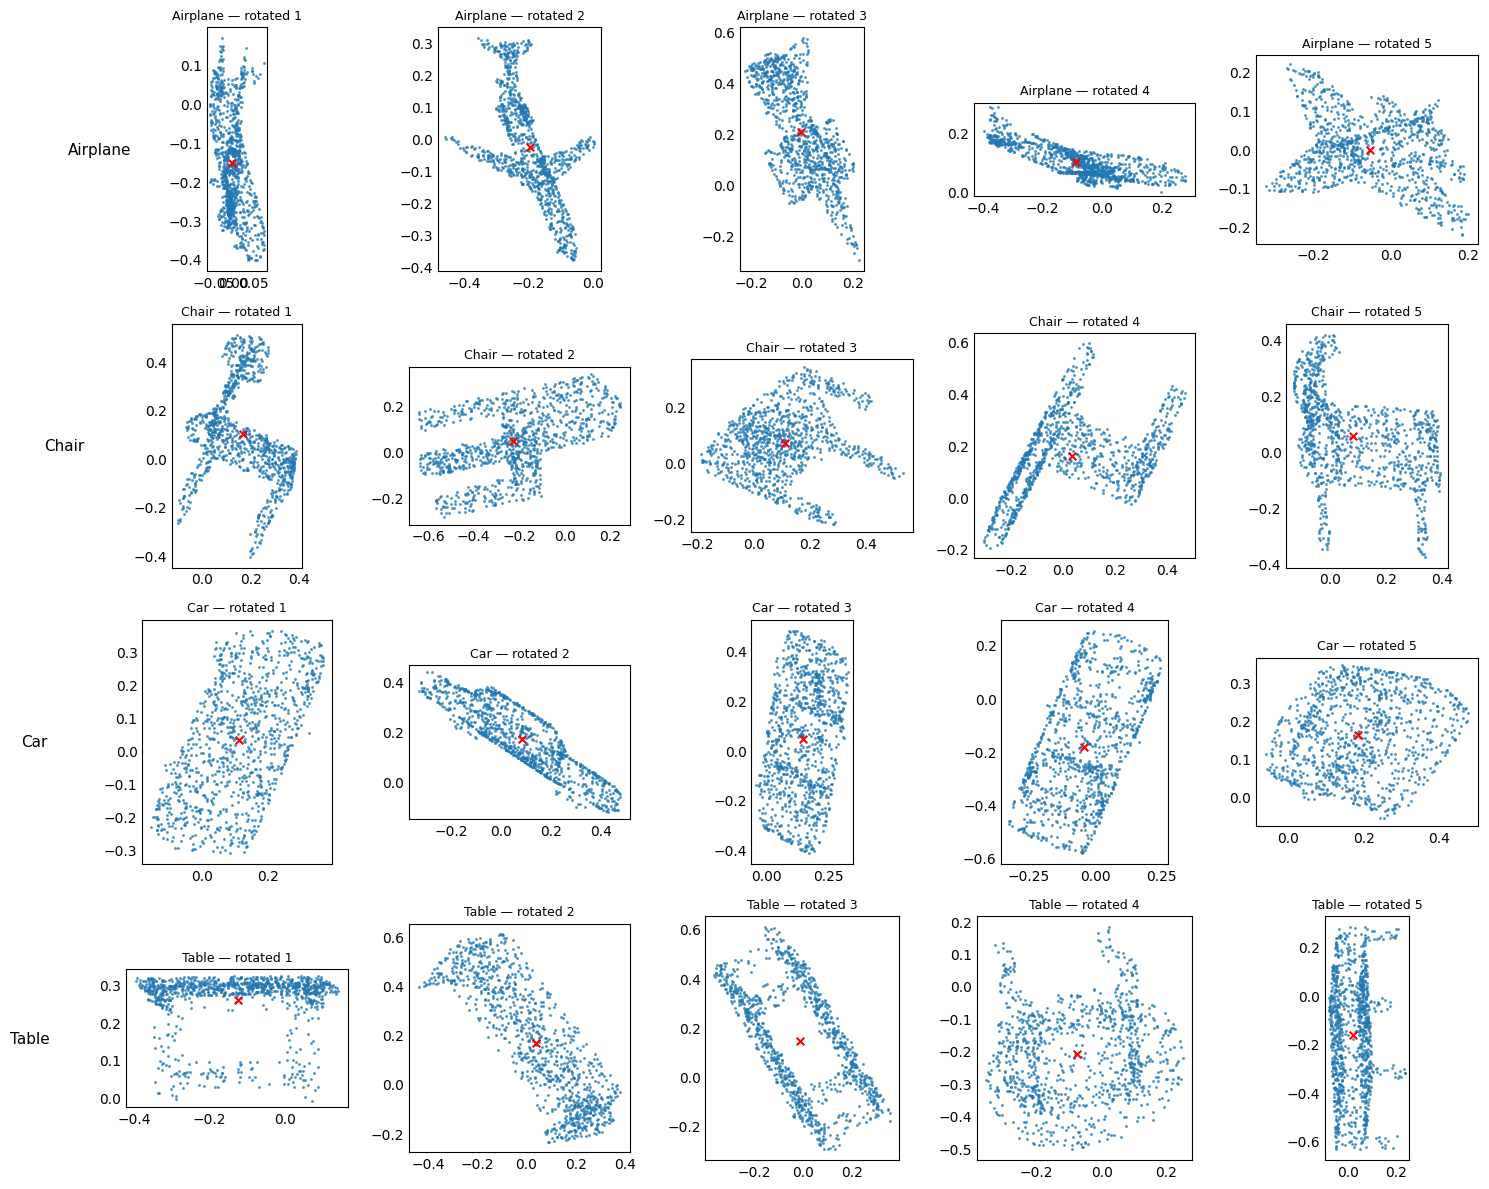

In [4]:
# ==================== CELL 2: Create Rotated Samples ====================

print("="*80)
print("CREATING ROTATED POINT CLOUDS")
print("="*80)

rotated_samples = {}

for class_name in selected_classes:
    rotated_samples[class_name] = []
    
    print(f"\n{class_name} (Class ID: {class_name_id_map[class_name]}):")
    
    for i, sample in enumerate(class_samples[class_name][:5]):
        # Apply random transformation
        rotated = apply_random_transformation(sample['points'])
        rotated_samples[class_name].append(rotated)
        
        print(f"  Sample {i+1}:")
        print(f"    Shape: {rotated.shape}")
        print(f"    Centroid: [{rotated.mean(axis=0)[0]:.3f}, {rotated.mean(axis=0)[1]:.3f}, {rotated.mean(axis=0)[2]:.3f}]")

# Plot rotated samples
print("\n" + "="*80)
print("PLOTTING ROTATED SAMPLES")
print("="*80)

rows = len(selected_classes)
cols = 5

fig, axes = plt.subplots(rows, cols, figsize=(cols*3.0, rows*3.0), squeeze=False)

for r, class_name in enumerate(selected_classes):
    for c in range(cols):
        ax = axes[r][c]
        if c < len(rotated_samples[class_name]):
            pts = rotated_samples[class_name][c]
            x = pts[:, 0]
            y = pts[:, 1]
            ax.scatter(x, y, s=1.5, alpha=0.6)
            cx, cy = pts.mean(axis=0)[:2]
            ax.scatter([cx], [cy], marker='x', s=30, color='red')
            ax.set_title(f"{class_name} — rotated {c+1}", fontsize=9)
            ax.set_aspect('equal', 'box')
            ax.tick_params(axis='both', which='both', length=0)
        else:
            ax.axis('off')

for r, class_name in enumerate(selected_classes):
    axes[r][0].set_ylabel(class_name, rotation=0, labelpad=50, va='center', fontsize=11)

plt.tight_layout()
plt.show()

NORMALIZING ROTATED SAMPLES

Airplane:
  Sample 1:
    Shape: (1024, 3)
    Centroid: [ 3.03576608e-18 -3.98986399e-17 -1.86482774e-17]
    Max distance: 1.000000
  Sample 2:
    Shape: (1024, 3)
    Centroid: [ 5.24753851e-17 -4.33680869e-18  2.23345648e-17]
    Max distance: 1.000000
  Sample 3:
    Shape: (1024, 3)
    Centroid: [ 5.20417043e-18 -2.77555756e-17  2.76471554e-17]
    Max distance: 1.000000
  Sample 4:
    Shape: (1024, 3)
    Centroid: [-1.73472348e-18  1.86482774e-17 -2.16840434e-18]
    Max distance: 1.000000
  Sample 5:
    Shape: (1024, 3)
    Centroid: [ 1.30104261e-17 -7.80625564e-18  4.33680869e-18]
    Max distance: 1.000000

Chair:
  Sample 1:
    Shape: (1024, 3)
    Centroid: [-8.89045781e-18 -1.12757026e-17  1.19262239e-17]
    Max distance: 1.000000
  Sample 2:
    Shape: (1024, 3)
    Centroid: [ 4.07660017e-17 -8.89045781e-18  8.23993651e-18]
    Max distance: 1.000000
  Sample 3:
    Shape: (1024, 3)
    Centroid: [-2.77555756e-17  5.63785130e-18 -1.21

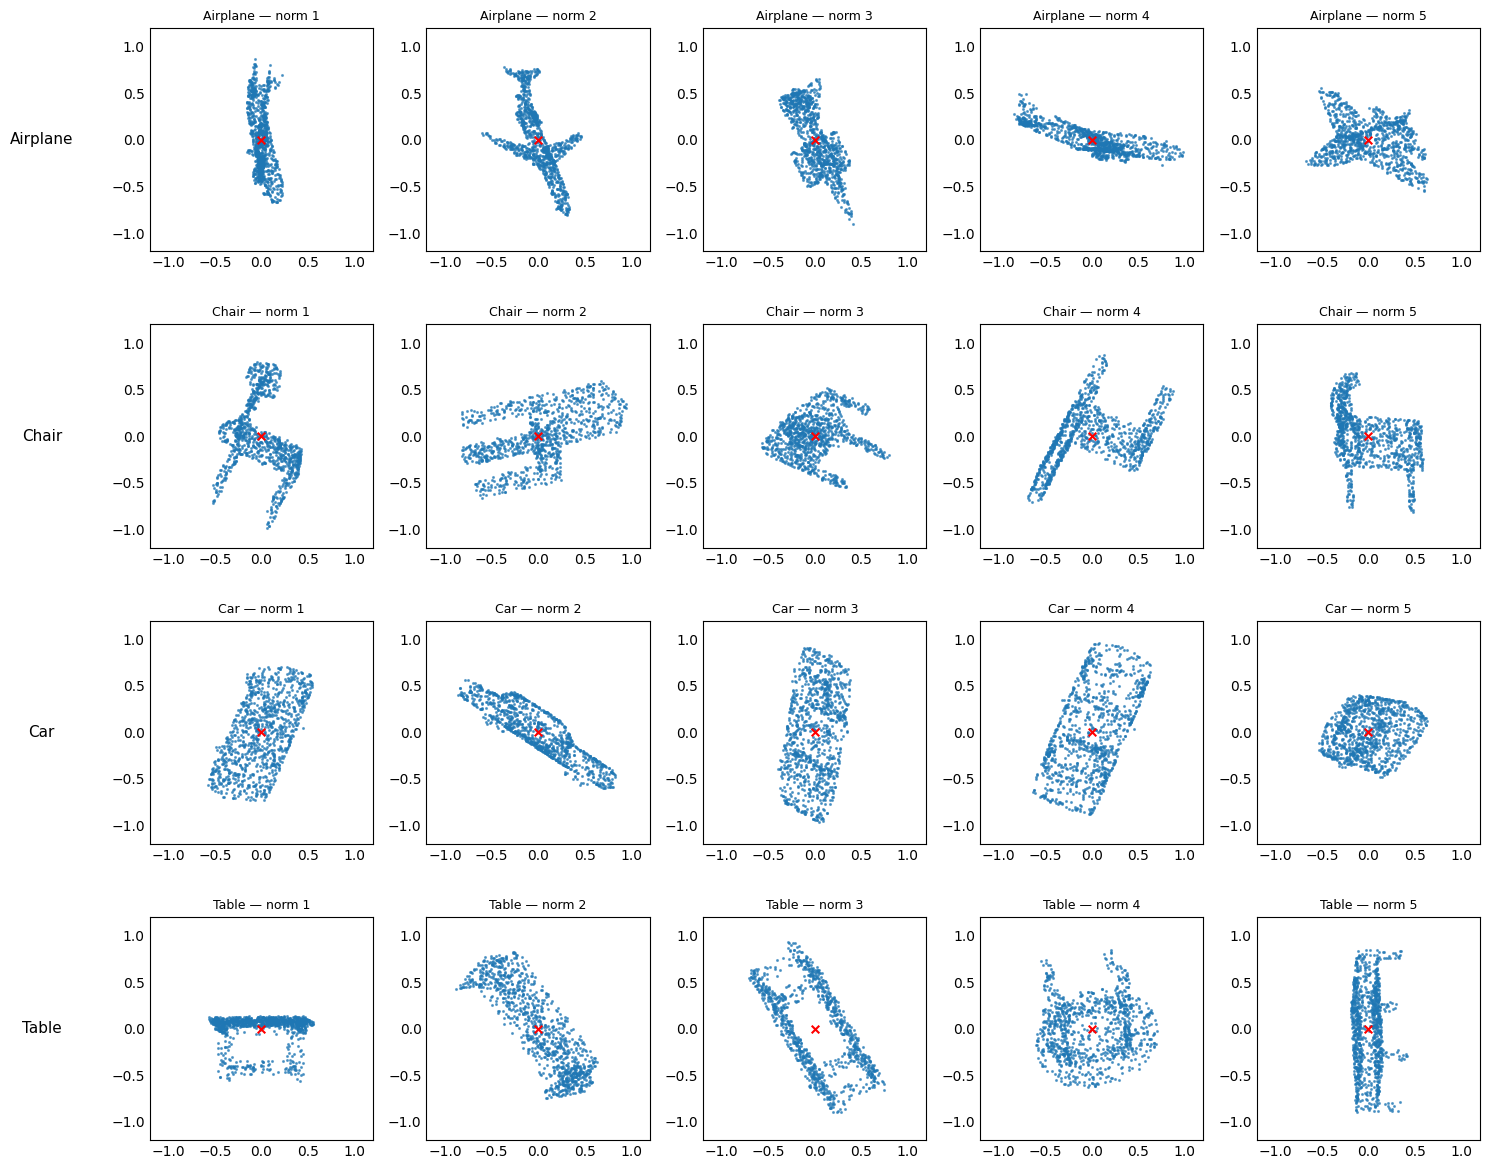

In [5]:
# ==================== CELL 3: Normalize Rotated Samples ====================

print("="*80)
print("NORMALIZING ROTATED SAMPLES")
print("="*80)

normalized_samples = {}

for class_name in selected_classes:
    normalized_samples[class_name] = []
    
    print(f"\n{class_name}:")
    
    for i, rotated_pc in enumerate(rotated_samples[class_name]):
        normalized = normalize_point_cloud(rotated_pc)
        normalized_samples[class_name].append(normalized)
        
        print(f"  Sample {i+1}:")
        print(f"    Shape: {normalized.shape}")
        print(f"    Centroid: {np.mean(normalized, axis=0)}")
        print(f"    Max distance: {np.max(np.linalg.norm(normalized, axis=1)):.6f}")

# Plot normalized samples
print("\n" + "="*80)
print("PLOTTING NORMALIZED SAMPLES")
print("="*80)

fig, axes = plt.subplots(rows, cols, figsize=(cols*3.0, rows*3.0), squeeze=False)

for r, class_name in enumerate(selected_classes):
    for c in range(cols):
        ax = axes[r][c]
        if c < len(normalized_samples[class_name]):
            pts = normalized_samples[class_name][c]
            x = pts[:, 0]
            y = pts[:, 1]
            ax.scatter(x, y, s=1.5, alpha=0.6)
            cx, cy = pts.mean(axis=0)[:2]
            ax.scatter([cx], [cy], marker='x', s=30, color='red')
            ax.set_title(f"{class_name} — norm {c+1}", fontsize=9)
            ax.set_aspect('equal', 'box')
            ax.tick_params(axis='both', which='both', length=0)
            ax.set_xlim([-1.2, 1.2])
            ax.set_ylim([-1.2, 1.2])
        else:
            ax.axis('off')

for r, class_name in enumerate(selected_classes):
    axes[r][0].set_ylabel(class_name, rotation=0, labelpad=50, va='center', fontsize=11)

plt.tight_layout()
plt.show()

In [6]:
# ==================== CELL 4: Weight Matrix (CORRECTED) ====================

def compute_weight_matrix(X, t=1.0):
    """
    Compute heat kernel weight matrix (Equation 1).
    
    W_ij = exp(-||x_i - x_j||² / (2t))
    
    Args:
        X: Point cloud (N, 3)
        t: Temperature parameter (default: 1.0)
    
    Returns:
        W: Weight matrix (N, N)
    """
    dists = cdist(X, X, metric='euclidean')
    dists_sq = dists ** 2
    W = np.exp(-dists_sq / (2.0 * t))
    return W

print("="*80)
print("WEIGHT MATRIX COMPUTATION (CORRECTED)")
print("="*80)

sample_pc = normalized_samples['Airplane'][0]
print(f"\nInput shape: {sample_pc.shape}")

W = compute_weight_matrix(sample_pc, t=1.0)
print(f"Weight matrix shape: {W.shape}")
print(f"Weight matrix min: {W.min():.6f}, max: {W.max():.6f}")
print(f"Weight matrix diagonal (should be 1.0): {W.diagonal()[:5]}")

WEIGHT MATRIX COMPUTATION (CORRECTED)

Input shape: (1024, 3)
Weight matrix shape: (1024, 1024)
Weight matrix min: 0.177742, max: 1.000000
Weight matrix diagonal (should be 1.0): [1. 1. 1. 1. 1.]


In [7]:
# ==================== CELL 5: Normalized Laplacian (CORRECTED) ====================

def compute_normalized_laplacian(W):
    """
    Compute normalized graph Laplacian.
    
    L = I - Δ^{-1/2} W Δ^{-1/2}
    
    Note: Paper writes Eq. 2 as L = Δ^{-1/2}WΔ^{-1/2} but references
    standard normalized Laplacian literature. We use the standard form
    which has eigenvalues in [0, 2] and smallest eigenvalue ≈ 0.
    
    Args:
        W: Weight matrix (N, N)
    
    Returns:
        L: Normalized Laplacian (N, N)
    """
    N = W.shape[0]
    eps = 1e-10
    
    # Degree matrix diagonal
    D = np.sum(W, axis=1)
    
    # D^{-1/2} with numerical stability
    D_inv_sqrt = np.zeros(N)
    mask = D > eps
    D_inv_sqrt[mask] = 1.0 / np.sqrt(D[mask])
    
    # Compute normalized Laplacian
    D_inv_sqrt_mat = np.diag(D_inv_sqrt)
    L = np.eye(N) - D_inv_sqrt_mat @ W @ D_inv_sqrt_mat
    
    return L

print("="*80)
print("NORMALIZED LAPLACIAN (CORRECTED)")
print("="*80)

sample_pc = normalized_samples['Airplane'][0]
W = compute_weight_matrix(sample_pc, t=1.0)
L = compute_normalized_laplacian(W)

print(f"\nLaplacian shape: {L.shape}")
print(f"Laplacian min: {L.min():.6f}, max: {L.max():.6f}")
print(f"Is symmetric: {np.allclose(L, L.T)}")
print(f"Diagonal elements (first 5): {L.diagonal()[:5]}")

NORMALIZED LAPLACIAN (CORRECTED)

Laplacian shape: (1024, 1024)
Laplacian min: -0.001712, max: 0.998903
Is symmetric: True
Diagonal elements (first 5): [0.99882699 0.99874751 0.99888485 0.99879293 0.99884223]


In [8]:
# ==================== CELL 6: Eigendecomposition ====================

from scipy.linalg import eigh

def compute_laplacian_eigenvector(L):
    """
    Compute eigenvector corresponding to smallest non-zero eigenvalue.
    With corrected Laplacian, eigenvalues should be in [0, 2].
    """
    eigenvalues, eigenvectors = eigh(L)
    return eigenvalues, eigenvectors

print("="*80)
print("EIGENDECOMPOSITION")
print("="*80)

sample_pc = normalized_samples['Airplane'][0]
W = compute_weight_matrix(sample_pc, t=1.0)
L = compute_normalized_laplacian(W)

eigenvalues, eigenvectors = compute_laplacian_eigenvector(L)

print(f"\nEigenvalues shape: {eigenvalues.shape}")
print(f"Eigenvectors shape: {eigenvectors.shape}")

print(f"\nFirst 10 eigenvalues (sorted ascending):")
print(eigenvalues[:10])

print(f"\n** Paper: Use 2nd smallest eigenvalue's eigenvector **")
print(f"   λ[0] (smallest, should be ≈0): {eigenvalues[0]:.8f}")
print(f"   λ[1] (2nd smallest - USE THIS): {eigenvalues[1]:.8f}")
print(f"   λ[2] (3rd smallest): {eigenvalues[2]:.8f}")

phi = eigenvectors[:, 1]
print(f"\nSelected eigenvector φ shape: {phi.shape}")
print(f"Eigenvector values (first 10): {phi[:10]}")
print(f"Eigenvector min: {phi.min():.6f}, max: {phi.max():.6f}")

EIGENDECOMPOSITION

Eigenvalues shape: (1024,)
Eigenvectors shape: (1024, 1024)

First 10 eigenvalues (sorted ascending):
[2.22044605e-16 8.53935528e-01 9.28431581e-01 9.80556295e-01
 9.92167554e-01 9.96611220e-01 9.96905019e-01 9.98778879e-01
 9.99358420e-01 9.99509936e-01]

** Paper: Use 2nd smallest eigenvalue's eigenvector **
   λ[0] (smallest, should be ≈0): 0.00000000
   λ[1] (2nd smallest - USE THIS): 0.85393553
   λ[2] (3rd smallest): 0.92843158

Selected eigenvector φ shape: (1024,)
Eigenvector values (first 10): [ 0.03100069  0.04439947 -0.00132021 -0.03687084  0.02768775 -0.02707145
  0.03842939 -0.01471375 -0.00702164  0.06240475]
Eigenvector min: -0.059088, max: 0.067136


CANONICAL ORDERING (CORRECTED)

Eigenvector after sign normalization:
  Min: -0.059088, Max: 0.067136
  Max-magnitude entry: 0.067136 (should be positive)

Permutation indices shape: (1024,)
Permutation matrix shape: (1024, 1024)
First 10 permutation indices: [911 120 327 914 285 303 223 913 573 768]
Sorted eigenvector values (first 10): [-0.05908772 -0.05838398 -0.05801009 -0.05714892 -0.05710766 -0.05649568
 -0.05637432 -0.05612393 -0.05610901 -0.05610218]

Original shape: (1024, 3)
Ordered shape: (1024, 3)


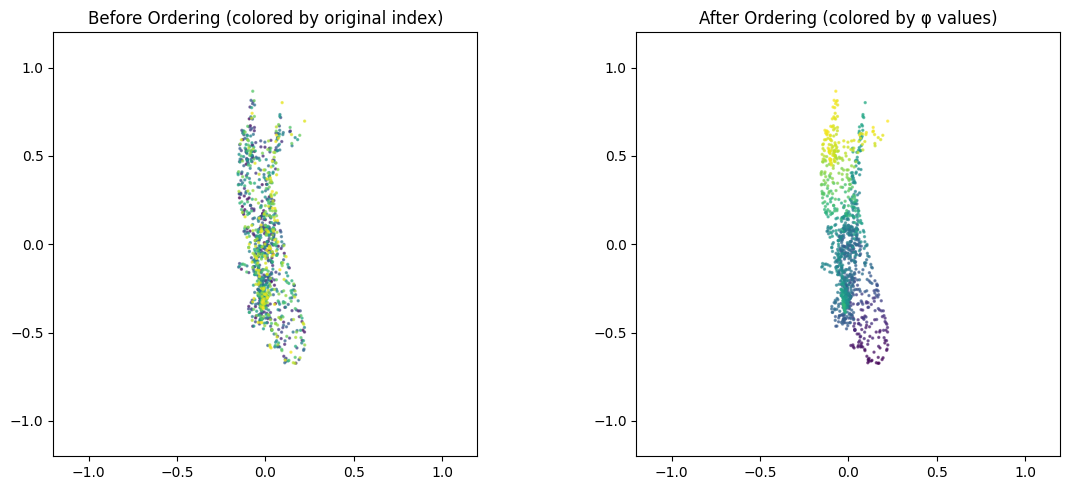

In [9]:
# ==================== CELL 7: Canonical Ordering (CORRECTED) ====================

def compute_canonical_ordering(phi):
    """
    Create canonical ordering from eigenvector.
    
    Steps:
    1. Normalize sign: largest-magnitude entry → positive
    2. Sort points by eigenvector values ascending
    
    Args:
        phi: Eigenvector (N,)
    
    Returns:
        sigma: Permutation indices (N,)
        Pi: Permutation matrix (N, N)
        phi: Sign-normalized eigenvector (N,)
    """
    phi = phi.copy()  # Don't modify original
    
    # Normalize sign (per paper proof)
    max_abs_idx = np.argmax(np.abs(phi))
    if phi[max_abs_idx] < 0:
        phi = -phi
    
    # Sort indices by eigenvector values
    sigma = np.argsort(phi)
    
    # Create permutation matrix
    N = len(phi)
    Pi = np.zeros((N, N))
    for i, j in enumerate(sigma):
        Pi[i, j] = 1.0
    
    return sigma, Pi, phi
    
print("="*80)
print("CANONICAL ORDERING (CORRECTED)")
print("="*80)

sample_pc = normalized_samples['Airplane'][0]
W = compute_weight_matrix(sample_pc, t=1.0)
L = compute_normalized_laplacian(W)
eigenvalues, eigenvectors = compute_laplacian_eigenvector(L)
phi = eigenvectors[:, 1].copy()

sigma, Pi, phi_normalized = compute_canonical_ordering(phi)

print(f"\nEigenvector after sign normalization:")
print(f"  Min: {phi_normalized.min():.6f}, Max: {phi_normalized.max():.6f}")
print(f"  Max-magnitude entry: {phi_normalized[np.argmax(np.abs(phi_normalized))]:.6f} (should be positive)")

print(f"\nPermutation indices shape: {sigma.shape}")
print(f"Permutation matrix shape: {Pi.shape}")
print(f"First 10 permutation indices: {sigma[:10]}")
print(f"Sorted eigenvector values (first 10): {phi_normalized[sigma[:10]]}")

# Apply permutation
X_ordered = sample_pc[sigma]
print(f"\nOriginal shape: {sample_pc.shape}")
print(f"Ordered shape: {X_ordered.shape}")

# Plot before and after ordering
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(sample_pc[:, 0], sample_pc[:, 1], c=np.arange(len(sample_pc)), 
                s=2, alpha=0.6, cmap='viridis')
axes[0].set_title('Before Ordering (colored by original index)')
axes[0].set_aspect('equal')
axes[0].set_xlim([-1.2, 1.2])
axes[0].set_ylim([-1.2, 1.2])

axes[1].scatter(X_ordered[:, 0], X_ordered[:, 1], c=phi_normalized[sigma], 
                s=2, alpha=0.6, cmap='viridis')
axes[1].set_title('After Ordering (colored by φ values)')
axes[1].set_aspect('equal')
axes[1].set_xlim([-1.2, 1.2])
axes[1].set_ylim([-1.2, 1.2])

plt.tight_layout()
plt.show()

R1 ROTATION

Center of mass: [-8.80914265e-18 -7.70867745e-17  1.05276031e-16]
Center of mass norm: 0.000000

R1 shape: (3, 3)
R1 is orthogonal: True
det(R1) = 1: True

After R1:
  New center of mass: [ 3.46944695e-18 -2.77555756e-17 -2.77555756e-17]
  Expected: [0, 0, 0.000000]
  Y shape: (1024, 3)


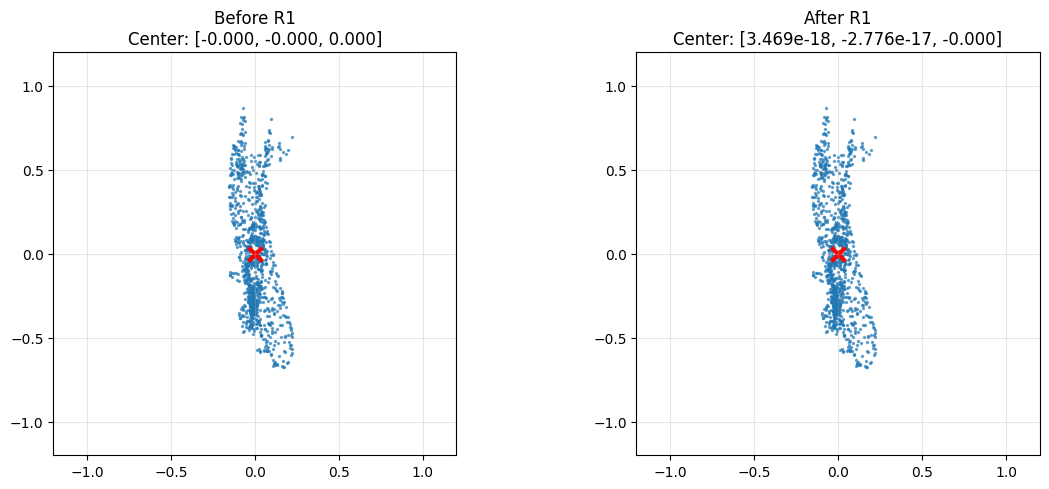

In [10]:
# ==================== CELL 8: R1 Rotation ====================

def compute_R1(m):
    """
    Compute R1 that aligns center of mass to positive z-axis.
    
    Transformation: R1 · m = [0, 0, ||m||]
    Uses Rodrigues' rotation formula.
    
    Args:
        m: Center of mass vector (3,)
    
    Returns:
        R1: Rotation matrix (3, 3)
    """
    eps = 1e-10
    m_norm = np.linalg.norm(m)
    
    # Handle zero vector
    if m_norm < eps:
        return np.eye(3)
    
    m_unit = m / m_norm
    target = np.array([0.0, 0.0, 1.0])
    
    # Check if already aligned
    cos_theta = np.dot(m_unit, target)
    
    if abs(cos_theta - 1.0) < eps:
        return np.eye(3)
    
    # Check if opposite direction (180° rotation)
    if abs(cos_theta + 1.0) < eps:
        return np.array([[1.0, 0.0, 0.0],
                        [0.0, -1.0, 0.0],
                        [0.0, 0.0, -1.0]])
    
    # Compute rotation axis (perpendicular to m and target)
    axis = np.cross(m_unit, target)
    axis_norm = np.linalg.norm(axis)
    
    if axis_norm < eps:
        return np.eye(3)
    
    k = axis / axis_norm
    
    # Rodrigues' formula: R = I + sin(θ)K + (1-cos(θ))K²
    theta = np.arccos(np.clip(cos_theta, -1.0, 1.0))
    
    # Skew-symmetric matrix K
    K = np.array([[0.0, -k[2], k[1]],
                  [k[2], 0.0, -k[0]],
                  [-k[1], k[0], 0.0]])
    
    I = np.eye(3)
    sin_theta = np.sin(theta)
    cos_term = 1.0 - cos_theta
    
    R1 = I + sin_theta * K + cos_term * (K @ K)
    
    return R1

print("="*80)
print("R1 ROTATION")
print("="*80)

sample_pc = normalized_samples['Airplane'][0]
W = compute_weight_matrix(sample_pc, t=1.0)
L = compute_normalized_laplacian(W)
eigenvalues, eigenvectors = compute_laplacian_eigenvector(L)
phi = eigenvectors[:, 1].copy()
sigma, Pi, phi_normalized = compute_canonical_ordering(phi)
X_ordered = sample_pc[sigma]

# Compute center of mass
m = np.mean(X_ordered, axis=0)
print(f"\nCenter of mass: {m}")
print(f"Center of mass norm: {np.linalg.norm(m):.6f}")

# Compute R1
R1 = compute_R1(m)
print(f"\nR1 shape: {R1.shape}")
print(f"R1 is orthogonal: {np.allclose(R1 @ R1.T, np.eye(3))}")
print(f"det(R1) = 1: {np.isclose(np.linalg.det(R1), 1.0)}")

# Apply R1
Y = (R1 @ X_ordered.T).T
new_m = np.mean(Y, axis=0)
print(f"\nAfter R1:")
print(f"  New center of mass: {new_m}")
print(f"  Expected: [0, 0, {np.linalg.norm(m):.6f}]")
print(f"  Y shape: {Y.shape}")

# Plot before and after R1
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(X_ordered[:, 0], X_ordered[:, 1], s=2, alpha=0.6)
axes[0].scatter([m[0]], [m[1]], marker='x', s=100, color='red', linewidths=3)
axes[0].set_title(f'Before R1\nCenter: [{m[0]:.3f}, {m[1]:.3f}, {m[2]:.3f}]')
axes[0].set_aspect('equal')
axes[0].set_xlim([-1.2, 1.2])
axes[0].set_ylim([-1.2, 1.2])
axes[0].grid(alpha=0.3)

axes[1].scatter(Y[:, 0], Y[:, 1], s=2, alpha=0.6)
axes[1].scatter([new_m[0]], [new_m[1]], marker='x', s=100, color='red', linewidths=3)
axes[1].set_title(f'After R1\nCenter: [{new_m[0]:.3e}, {new_m[1]:.3e}, {new_m[2]:.3f}]')
axes[1].set_aspect('equal')
axes[1].set_xlim([-1.2, 1.2])
axes[1].set_ylim([-1.2, 1.2])
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

R2 ROTATION

Landmark point index: 1023
Landmark coordinates in Y: [ 0.22249689  0.69739582 -0.60063635]
Landmark eigenvector value: 0.067136

R2 shape: (3, 3)
R2 is orthogonal: True
det(R2) = 1: True

After R2:
  Landmark: [ 7.32028544e-01 -7.95393388e-17 -6.00636346e-01]
  y-coordinate: -0.00000000 (should be ≈0)
  x-coordinate: 0.732029 (should be >0)
  P shape: (1024, 3)


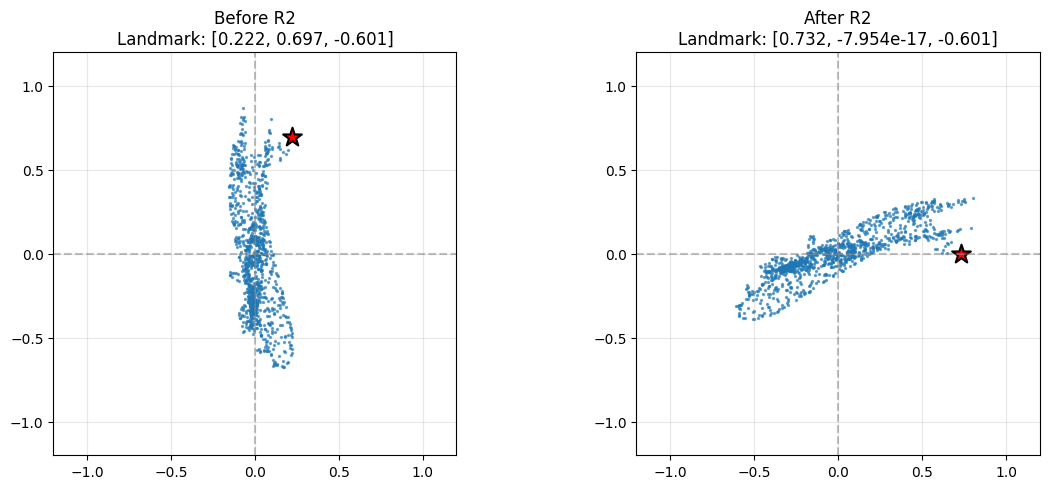

In [11]:
# ==================== CELL 9: R2 Rotation ====================

def compute_R2(p1):
    """
    Compute R2 that rotates landmark to XZ-plane with positive x.
    
    Rotates about z-axis only to preserve R1's alignment.
    
    Args:
        p1: Landmark point coordinates (3,)
    
    Returns:
        R2: Rotation matrix (3, 3)
    """
    eps = 1e-10
    x1, y1, z1 = p1
    
    # Check if already in XZ-plane
    if np.abs(y1) < eps:
        if x1 > 0:
            return np.eye(3)
        else:
            # Need 180° rotation if negative x
            return np.array([[-1.0, 0.0, 0.0],
                             [0.0, -1.0, 0.0],
                             [0.0, 0.0, 1.0]])
    
    # Compute rotation angle from current position to positive x-axis
    theta = np.arctan2(y1, x1)
    cos_theta = np.cos(theta)
    sin_theta = np.sin(theta)
    
    # Rotation matrix about z-axis by angle -theta
    R2 = np.array([[cos_theta, sin_theta, 0.0],
                   [-sin_theta, cos_theta, 0.0],
                   [0.0, 0.0, 1.0]])
    
    return R2

print("="*80)
print("R2 ROTATION")
print("="*80)

sample_pc = normalized_samples['Airplane'][0]
W = compute_weight_matrix(sample_pc, t=1.0)
L = compute_normalized_laplacian(W)
eigenvalues, eigenvectors = compute_laplacian_eigenvector(L)
phi = eigenvectors[:, 1].copy()
sigma, Pi, phi_normalized = compute_canonical_ordering(phi)
X_ordered = sample_pc[sigma]
m = np.mean(X_ordered, axis=0)
R1 = compute_R1(m)
Y = (R1 @ X_ordered.T).T

# Find landmark point (maximum eigenvector value)
p1_idx = len(phi_normalized) - 1
p1 = Y[p1_idx]

print(f"\nLandmark point index: {p1_idx}")
print(f"Landmark coordinates in Y: {p1}")
print(f"Landmark eigenvector value: {phi_normalized[sigma[p1_idx]]:.6f}")

# Compute R2
R2 = compute_R2(p1)
print(f"\nR2 shape: {R2.shape}")
print(f"R2 is orthogonal: {np.allclose(R2 @ R2.T, np.eye(3))}")
print(f"det(R2) = 1: {np.isclose(np.linalg.det(R2), 1.0)}")

# Apply R2
P = (R2 @ Y.T).T
final_p1 = P[p1_idx]
print(f"\nAfter R2:")
print(f"  Landmark: {final_p1}")
print(f"  y-coordinate: {final_p1[1]:.8f} (should be ≈0)")
print(f"  x-coordinate: {final_p1[0]:.6f} (should be >0)")
print(f"  P shape: {P.shape}")

# Plot before and after R2
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(Y[:, 0], Y[:, 1], s=2, alpha=0.6)
axes[0].scatter([p1[0]], [p1[1]], marker='*', s=200, color='red', edgecolors='black', linewidths=1.5)
axes[0].axhline(y=0, color='gray', linestyle='--', alpha=0.5)
axes[0].axvline(x=0, color='gray', linestyle='--', alpha=0.5)
axes[0].set_title(f'Before R2\nLandmark: [{p1[0]:.3f}, {p1[1]:.3f}, {p1[2]:.3f}]')
axes[0].set_aspect('equal')
axes[0].set_xlim([-1.2, 1.2])
axes[0].set_ylim([-1.2, 1.2])
axes[0].grid(alpha=0.3)

axes[1].scatter(P[:, 0], P[:, 1], s=2, alpha=0.6)
axes[1].scatter([final_p1[0]], [final_p1[1]], marker='*', s=200, color='red', edgecolors='black', linewidths=1.5)
axes[1].axhline(y=0, color='gray', linestyle='--', alpha=0.5)
axes[1].axvline(x=0, color='gray', linestyle='--', alpha=0.5)
axes[1].set_title(f'After R2\nLandmark: [{final_p1[0]:.3f}, {final_p1[1]:.3e}, {final_p1[2]:.3f}]')
axes[1].set_aspect('equal')
axes[1].set_xlim([-1.2, 1.2])
axes[1].set_ylim([-1.2, 1.2])
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [12]:
# ==================== CELL 10: Complete CanonNet Pipeline ====================

def canonnet_full_pipeline(X, t=1.0, verbose=False):
    """
    Complete CanonNet preprocessing pipeline (Equation 7).
    
    Transforms point cloud to canonical form:
    P = R2 · R1 · Π · X
    
    Args:
        X: Input point cloud (N, 3)
        t: Heat kernel temperature (default: 1.0)
        verbose: Print step information
    
    Returns:
        P: Canonical point cloud (N, 3)
        components: Dictionary with intermediate results
    """
    if verbose:
        print("Step 1: Computing weight matrix W (Eq. 1)")
    W = compute_weight_matrix(X, t)
    
    if verbose:
        print("Step 2: Computing normalized Laplacian L (Eq. 2)")
    L = compute_normalized_laplacian(W)
    
    if verbose:
        print("Step 3: Eigendecomposition - extracting Fiedler vector")
    eigenvalues, eigenvectors = eigh(L)
    phi = eigenvectors[:, 1].copy()  # 2nd smallest eigenvalue
    
    if verbose:
        print("Step 4: Canonical ordering Π (Eq. 3)")
    sigma, Pi, phi_normalized = compute_canonical_ordering(phi)
    X_ordered = X[sigma]
    
    if verbose:
        print("Step 5: R1 - align center of mass to z-axis (Eq. 5)")
    m = np.mean(X_ordered, axis=0)
    R1 = compute_R1(m)
    Y = (R1 @ X_ordered.T).T
    
    if verbose:
        print("Step 6: R2 - landmark to XZ-plane (Eq. 6)")
    # Landmark is point with largest eigenvector value
    p1_idx = len(sigma) - 1  # Last point after sorting
    p1 = Y[p1_idx]
    R2 = compute_R2(p1)
    P = (R2 @ Y.T).T
    
    return P, {
        'W': W,
        'L': L,
        'eigenvalues': eigenvalues,
        'eigenvectors': eigenvectors,
        'phi': phi_normalized,
        'sigma': sigma,
        'Pi': Pi,
        'X_ordered': X_ordered,
        'R1': R1,
        'Y': Y,
        'R2': R2,
        'P': P  # ← ADD THIS LINE
    }

print("="*80)
print("COMPLETE CANONNET PIPELINE")
print("="*80)

# Test on one sample
sample_pc = normalized_samples['Airplane'][0]
print(f"\nInput shape: {sample_pc.shape}")

P, components = canonnet_full_pipeline(sample_pc, t=1.0, verbose=True)

print(f"\nOutput shape: {P.shape}")
print(f"\nFinal statistics:")
print(f"  Centroid: {np.mean(P, axis=0)}")
print(f"  Centroid xy-distance: {np.sqrt(np.mean(P, axis=0)[0]**2 + np.mean(P, axis=0)[1]**2):.8f}")

# Verify landmark
landmark_idx = len(components['phi']) - 1
landmark = P[landmark_idx]
print(f"\nLandmark verification:")
print(f"  Coordinates: {landmark}")
print(f"  y ≈ 0: {np.abs(landmark[1]) < 1e-6}")
print(f"  x > 0: {landmark[0] > 0}")

COMPLETE CANONNET PIPELINE

Input shape: (1024, 3)
Step 1: Computing weight matrix W (Eq. 1)
Step 2: Computing normalized Laplacian L (Eq. 2)
Step 3: Eigendecomposition - extracting Fiedler vector
Step 4: Canonical ordering Π (Eq. 3)
Step 5: R1 - align center of mass to z-axis (Eq. 5)
Step 6: R2 - landmark to XZ-plane (Eq. 6)

Output shape: (1024, 3)

Final statistics:
  Centroid: [-4.16333634e-17 -1.38777878e-17 -2.77555756e-17]
  Centroid xy-distance: 0.00000000

Landmark verification:
  Coordinates: [ 7.32028544e-01 -7.95393388e-17 -6.00636346e-01]
  y ≈ 0: True
  x > 0: True


VISUALIZING ALL TRANSFORMATION STEPS


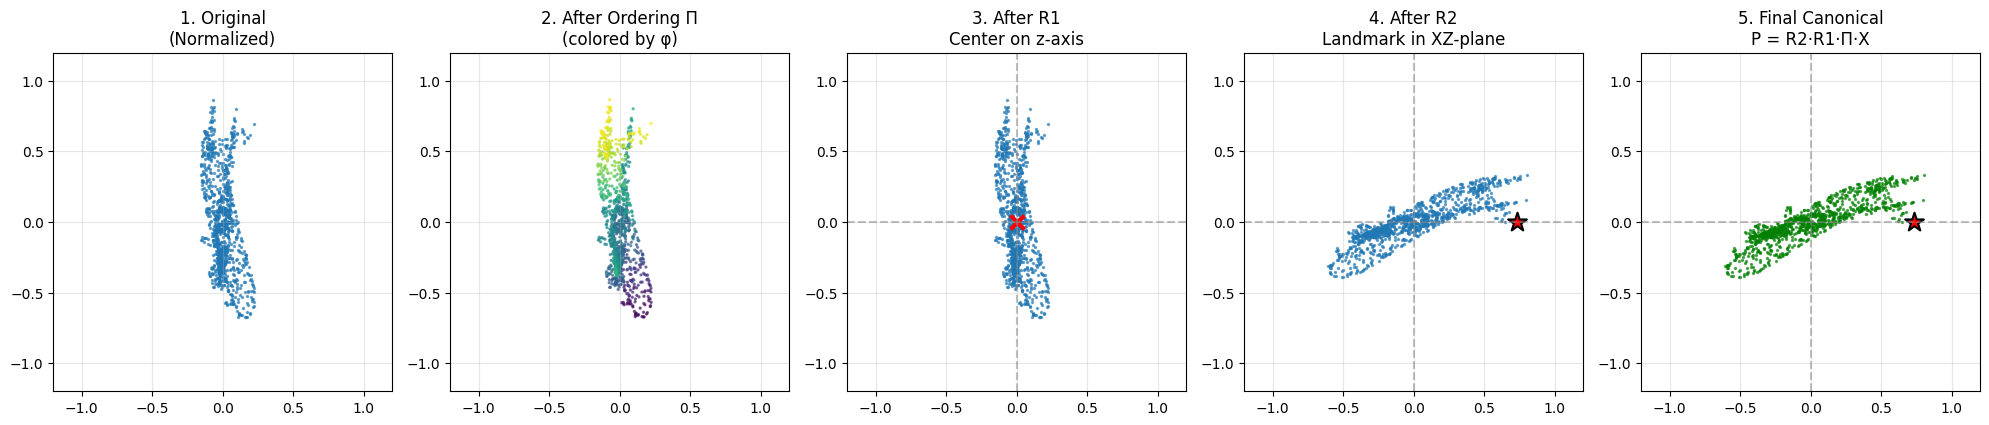

In [13]:
# ==================== CELL 11: Visualize All Steps ====================

print("="*80)
print("VISUALIZING ALL TRANSFORMATION STEPS")
print("="*80)

sample_pc = normalized_samples['Airplane'][0]
P, components = canonnet_full_pipeline(sample_pc, t=1.0, verbose=False)

# Create 5-panel plot showing all stages
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

# Original (normalized)
axes[0].scatter(sample_pc[:, 0], sample_pc[:, 1], s=2, alpha=0.6)
axes[0].set_title('1. Original\n(Normalized)')
axes[0].set_aspect('equal')
axes[0].set_xlim([-1.2, 1.2])
axes[0].set_ylim([-1.2, 1.2])
axes[0].grid(alpha=0.3)

# After Ordering
X_ordered = components['X_ordered']
axes[1].scatter(X_ordered[:, 0], X_ordered[:, 1], 
                c=components['phi'][components['sigma']], s=2, alpha=0.6, cmap='viridis')
axes[1].set_title('2. After Ordering Π\n(colored by φ)')
axes[1].set_aspect('equal')
axes[1].set_xlim([-1.2, 1.2])
axes[1].set_ylim([-1.2, 1.2])
axes[1].grid(alpha=0.3)

# After R1
Y = components['Y']
m = np.mean(Y, axis=0)
axes[2].scatter(Y[:, 0], Y[:, 1], s=2, alpha=0.6)
axes[2].scatter([m[0]], [m[1]], marker='x', s=100, color='red', linewidths=3)
axes[2].axhline(y=0, color='gray', linestyle='--', alpha=0.5)
axes[2].axvline(x=0, color='gray', linestyle='--', alpha=0.5)
axes[2].set_title(f'3. After R1\nCenter on z-axis')
axes[2].set_aspect('equal')
axes[2].set_xlim([-1.2, 1.2])
axes[2].set_ylim([-1.2, 1.2])
axes[2].grid(alpha=0.3)

# After R2
P = components['P']
landmark_idx = len(components['phi']) - 1
landmark = P[landmark_idx]
axes[3].scatter(P[:, 0], P[:, 1], s=2, alpha=0.6)
axes[3].scatter([landmark[0]], [landmark[1]], marker='*', s=200, 
                color='red', edgecolors='black', linewidths=1.5)
axes[3].axhline(y=0, color='gray', linestyle='--', alpha=0.5)
axes[3].axvline(x=0, color='gray', linestyle='--', alpha=0.5)
axes[3].set_title(f'4. After R2\nLandmark in XZ-plane')
axes[3].set_aspect('equal')
axes[3].set_xlim([-1.2, 1.2])
axes[3].set_ylim([-1.2, 1.2])
axes[3].grid(alpha=0.3)

# Final canonical form
axes[4].scatter(P[:, 0], P[:, 1], s=2, alpha=0.6, c='green')
axes[4].scatter([landmark[0]], [landmark[1]], marker='*', s=200, 
                color='red', edgecolors='black', linewidths=1.5)
axes[4].axhline(y=0, color='gray', linestyle='--', alpha=0.5)
axes[4].axvline(x=0, color='gray', linestyle='--', alpha=0.5)
axes[4].set_title(f'5. Final Canonical\nP = R2·R1·Π·X')
axes[4].set_aspect('equal')
axes[4].set_xlim([-1.2, 1.2])
axes[4].set_ylim([-1.2, 1.2])
axes[4].grid(alpha=0.3)

plt.tight_layout()
plt.show()

APPLYING CANONNET TO ALL SAMPLES

Airplane:
  Sample 1: (1024, 3)
  Sample 2: (1024, 3)
  Sample 3: (1024, 3)
  Sample 4: (1024, 3)
  Sample 5: (1024, 3)

Chair:
  Sample 1: (1024, 3)
  Sample 2: (1024, 3)
  Sample 3: (1024, 3)
  Sample 4: (1024, 3)
  Sample 5: (1024, 3)

Car:
  Sample 1: (1024, 3)
  Sample 2: (1024, 3)
  Sample 3: (1024, 3)
  Sample 4: (1024, 3)
  Sample 5: (1024, 3)

Table:
  Sample 1: (1024, 3)
  Sample 2: (1024, 3)
  Sample 3: (1024, 3)
  Sample 4: (1024, 3)
  Sample 5: (1024, 3)

PLOTTING CANONICAL SAMPLES


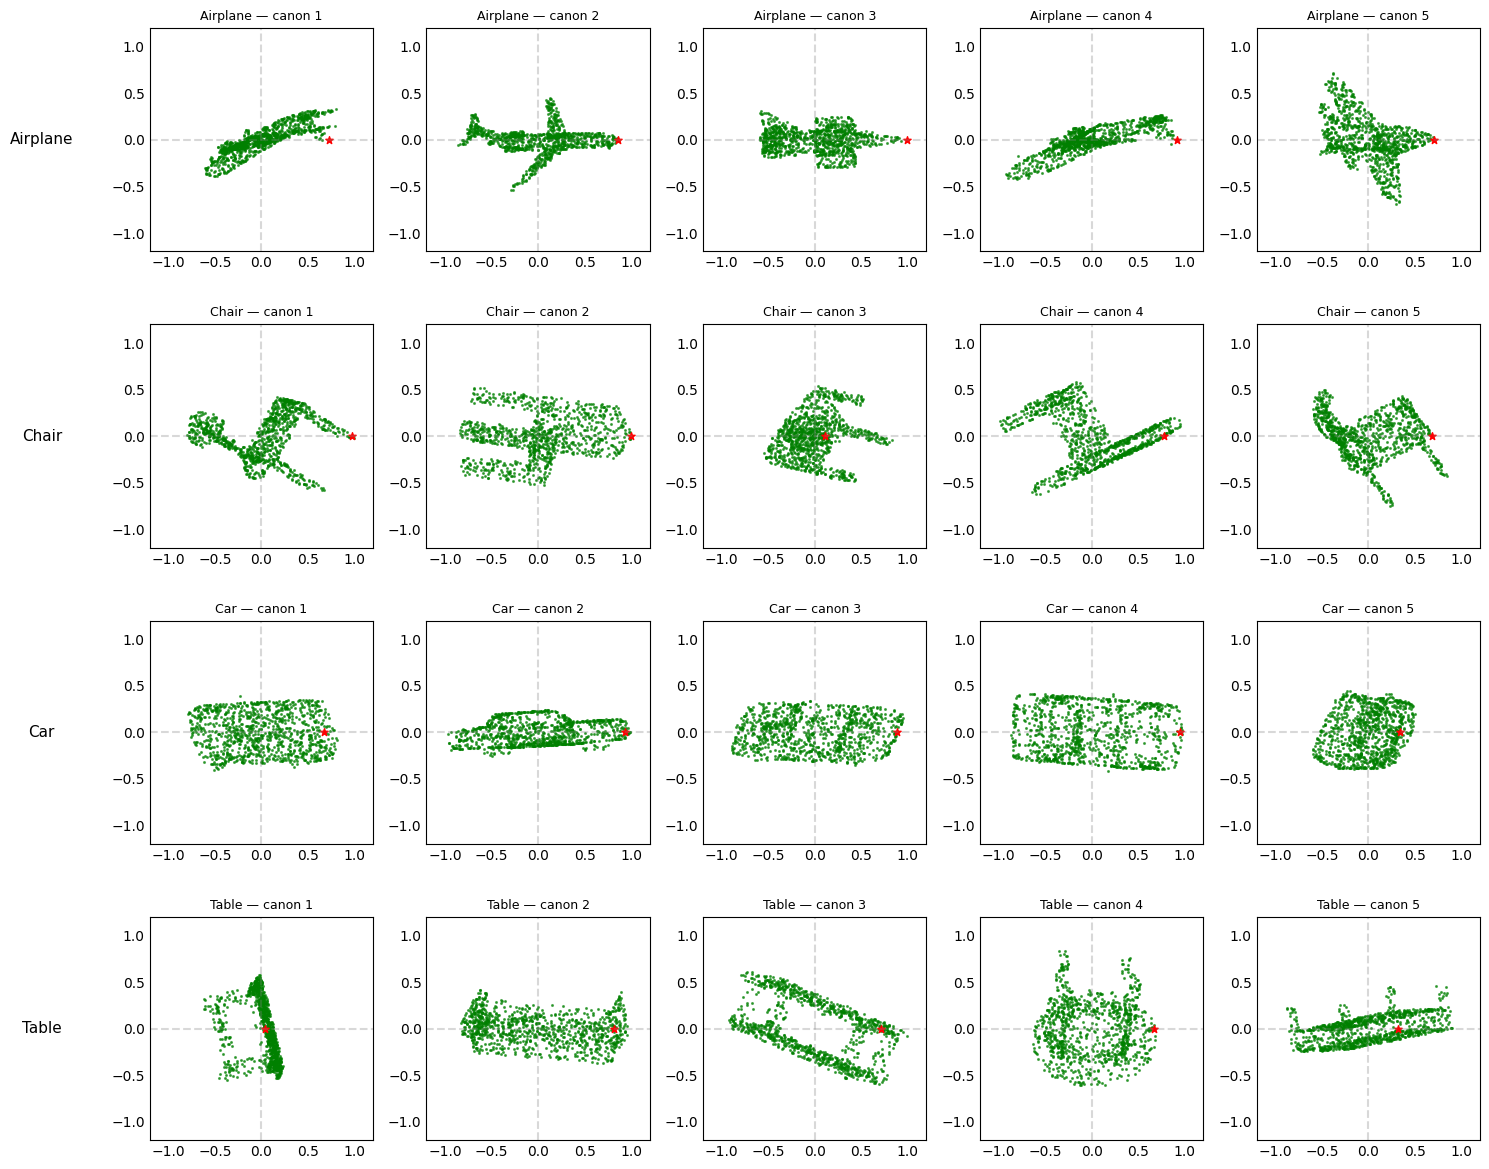

In [14]:
# ==================== CELL 12: Apply CanonNet to All Samples ====================

print("="*80)
print("APPLYING CANONNET TO ALL SAMPLES")
print("="*80)

canonical_samples = {}

for class_name in selected_classes:
    canonical_samples[class_name] = []
    
    print(f"\n{class_name}:")
    
    for i, normalized_pc in enumerate(normalized_samples[class_name]):
        P, _ = canonnet_full_pipeline(normalized_pc, t=1.0, verbose=False)
        canonical_samples[class_name].append(P)
        
        print(f"  Sample {i+1}: {P.shape}")

# Plot canonical samples
print("\n" + "="*80)
print("PLOTTING CANONICAL SAMPLES")
print("="*80)

rows = len(selected_classes)
cols = 5

fig, axes = plt.subplots(rows, cols, figsize=(cols*3.0, rows*3.0), squeeze=False)

for r, class_name in enumerate(selected_classes):
    for c in range(cols):
        ax = axes[r][c]
        if c < len(canonical_samples[class_name]):
            pts = canonical_samples[class_name][c]
            x = pts[:, 0]
            y = pts[:, 1]
            ax.scatter(x, y, s=1.5, alpha=0.6, c='green')
            # Mark landmark
            landmark_idx = len(pts) - 1
            ax.scatter([pts[landmark_idx, 0]], [pts[landmark_idx, 1]], 
                      marker='*', s=30, color='red')
            ax.axhline(y=0, color='gray', linestyle='--', alpha=0.3)
            ax.axvline(x=0, color='gray', linestyle='--', alpha=0.3)
            ax.set_title(f"{class_name} — canon {c+1}", fontsize=9)
            ax.set_aspect('equal', 'box')
            ax.tick_params(axis='both', which='both', length=0)
            ax.set_xlim([-1.2, 1.2])
            ax.set_ylim([-1.2, 1.2])
        else:
            ax.axis('off')

for r, class_name in enumerate(selected_classes):
    axes[r][0].set_ylabel(class_name, rotation=0, labelpad=50, va='center', fontsize=11)

plt.tight_layout()
plt.show()

In [15]:
# ==================== CELL 13: Chamfer Distance Comparison ====================

def chamfer_distance_detailed(pc1, pc2):
    """Chamfer Distance using cdist"""
    dists = cdist(pc1, pc2, metric='euclidean')
    min_dists_forward = np.min(dists, axis=1)
    forward = np.mean(min_dists_forward**2)
    min_dists_backward = np.min(dists, axis=0)
    backward = np.mean(min_dists_backward**2)
    cd = forward + backward
    return cd, forward, backward

print("="*80)
print("CHAMFER DISTANCE - BEFORE vs AFTER CANONNET")
print("="*80)

for class_name in selected_classes:
    print(f"\n{class_name}:")
    
    # Compare first 3 samples
    for i in range(3):
        for j in range(i+1, 3):
            # Before CanonNet
            pc1_before = normalized_samples[class_name][i]
            pc2_before = normalized_samples[class_name][j]
            cd_before, _, _ = chamfer_distance_detailed(pc1_before, pc2_before)
            
            # After CanonNet
            pc1_after = canonical_samples[class_name][i]
            pc2_after = canonical_samples[class_name][j]
            cd_after, _, _ = chamfer_distance_detailed(pc1_after, pc2_after)
            
            improvement = ((cd_before - cd_after) / cd_before) * 100
            
            print(f"  Sample {i+1} vs {j+1}:")
            print(f"    Before: {cd_before:.6f} → After: {cd_after:.6f}")
            print(f"    Improvement: {improvement:.1f}%")

CHAMFER DISTANCE - BEFORE vs AFTER CANONNET

Airplane:
  Sample 1 vs 2:
    Before: 0.138311 → After: 0.088426
    Improvement: 36.1%
  Sample 1 vs 3:
    Before: 0.062876 → After: 0.074220
    Improvement: -18.0%
  Sample 2 vs 3:
    Before: 0.062212 → After: 0.061380
    Improvement: 1.3%

Chair:
  Sample 1 vs 2:
    Before: 0.123099 → After: 0.053706
    Improvement: 56.4%
  Sample 1 vs 3:
    Before: 0.120941 → After: 0.079592
    Improvement: 34.2%
  Sample 2 vs 3:
    Before: 0.105602 → After: 0.086731
    Improvement: 17.9%

Car:
  Sample 1 vs 2:
    Before: 0.203404 → After: 0.136750
    Improvement: 32.8%
  Sample 1 vs 3:
    Before: 0.268744 → After: 0.224258
    Improvement: 16.6%
  Sample 2 vs 3:
    Before: 0.160102 → After: 0.019910
    Improvement: 87.6%

Table:
  Sample 1 vs 2:
    Before: 0.276777 → After: 0.333820
    Improvement: -20.6%
  Sample 1 vs 3:
    Before: 0.170214 → After: 0.170544
    Improvement: -0.2%
  Sample 2 vs 3:
    Before: 0.056085 → After: 0.1457

VISUAL COMPARISON: NORMALIZED vs CANONICAL


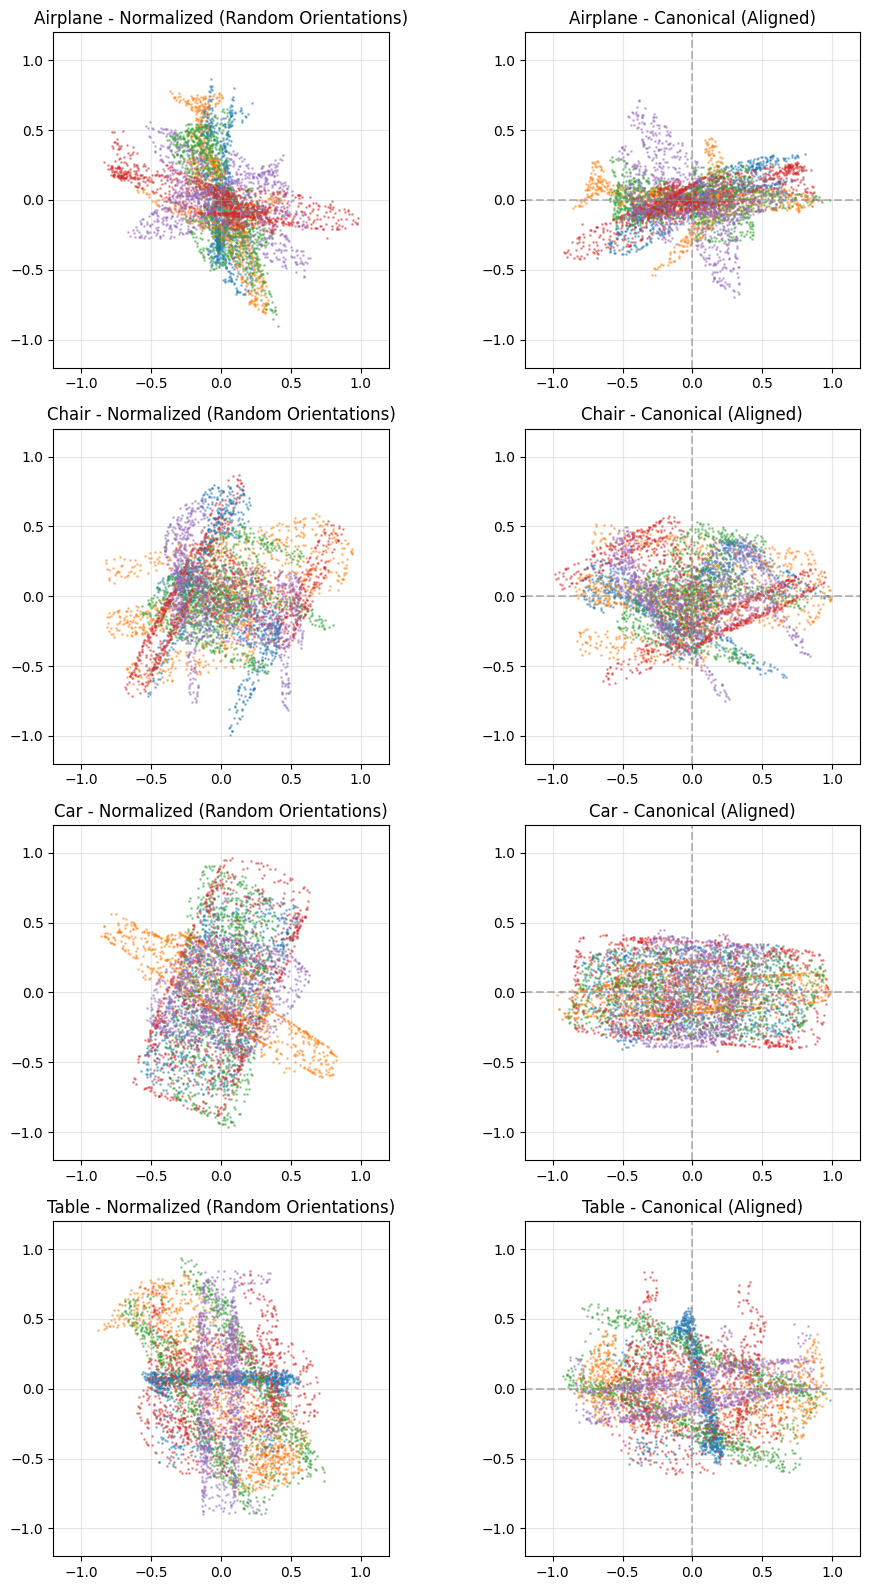

In [16]:
# ==================== CELL 14: Side-by-Side Comparison ====================

print("="*80)
print("VISUAL COMPARISON: NORMALIZED vs CANONICAL")
print("="*80)

fig, axes = plt.subplots(len(selected_classes), 2, 
                        figsize=(10, len(selected_classes)*4), squeeze=False)

for r, class_name in enumerate(selected_classes):
    # Plot normalized (before CanonNet)
    ax_norm = axes[r][0]
    for i in range(min(5, len(normalized_samples[class_name]))):
        pts = normalized_samples[class_name][i]
        ax_norm.scatter(pts[:, 0], pts[:, 1], s=1, alpha=0.4)
    ax_norm.set_title(f'{class_name} - Normalized (Random Orientations)')
    ax_norm.set_aspect('equal')
    ax_norm.set_xlim([-1.2, 1.2])
    ax_norm.set_ylim([-1.2, 1.2])
    ax_norm.grid(alpha=0.3)
    
    # Plot canonical (after CanonNet)
    ax_canon = axes[r][1]
    for i in range(min(5, len(canonical_samples[class_name]))):
        pts = canonical_samples[class_name][i]
        ax_canon.scatter(pts[:, 0], pts[:, 1], s=1, alpha=0.4)
    ax_canon.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
    ax_canon.axvline(x=0, color='gray', linestyle='--', alpha=0.5)
    ax_canon.set_title(f'{class_name} - Canonical (Aligned)')
    ax_canon.set_aspect('equal')
    ax_canon.set_xlim([-1.2, 1.2])
    ax_canon.set_ylim([-1.2, 1.2])
    ax_canon.grid(alpha=0.3)

plt.tight_layout()
plt.show()